#судоку


In [ ]:
import random

def generate_sudoku(clues):
    clues = max(17, min(81, clues))

    # Создаем базовую сетку одной формулой
    grid = [[(r*3 + r//3 + c) % 9 + 1 for c in range(9)] for r in range(9)]

    # Случайная замена цифр
    nums = list(range(1, 10))
    random.shuffle(nums)
    grid = [[nums[cell - 1] for cell in row] for row in grid]

    # Перемешиваем строки внутри блоков 3x3
    for i in (0, 3, 6):
        random.shuffle(grid[i:i+3])

    # Перемешиваем столбцы внутри блоков 3x3 (без транспонирования)
    for i in (0, 3, 6):
        cols = [[grid[r][c] for r in range(9)] for c in range(i, i+3)]
        random.shuffle(cols)
        for idx, c in enumerate(range(i, i+3)):
            for r in range(9):
                grid[r][c] = cols[idx][r]

    # Удаляем клетки через random.sample
    for r, c in random.sample([(r, c) for r in range(9) for c in range(9)], 81 - clues):
        grid[r][c] = '.'

    return grid

def print_grid(grid):
    for i, row in enumerate(grid):
        if i % 3 == 0 and i != 0:
            print("-" * 21)
        row_str = " ".join(str(x) for x in row)
        row_str = row_str[:5] + " | " + row_str[6:11] + " | " + row_str[12:]
        print(row_str)
    print()

sudoku = generate_sudoku(17)
print_grid(sudoku)

. 3 6 | . . . | . . .
. . . | . 2 . | . . 7
. . . | 3 . . | . 9 .
---------------------
3 . 7 | . . . | . . .
. . . | . . 2 | . . .
. 6 2 | . . . | . . .
---------------------
. . . | . 8 9 | . . .
. . . | . . . | . . 1
. . . | 4 1 . | . 2 .



In [ ]:
def find_empty(grid):
    for r in range(9):
        for c in range(9):
            if str(grid[r][c]) in ['.']:
                return (r, c)
    return None

def is_valid(grid, num, pos):
    num = str(num)
    r, c = pos

    for j in range(9):
        if str(grid[r][j]) == num:
            return False

    for i in range(9):
        if str(grid[i][c]) == num:
            return False

    box_r = (r // 3) * 3
    box_c = (c // 3) * 3
    for i in range(box_r, box_r + 3):
        for j in range(box_c, box_c + 3):
            if str(grid[i][j]) == num:
                return False
    return True

def solve(grid):
    empty = find_empty(grid)
    if not empty:
        return True

    r, c = empty
    for num in [str(i) for i in range(1, 10)]:
        if is_valid(grid, num, (r, c)):
            grid[r][c] = num
            if solve(grid):
                return True
            grid[r][c] = '.'
    return False

sudoku = generate_sudoku(17)
print("Сгенерированное судоку:")
print_grid(sudoku)

print("Решение:")
solve(sudoku)
print_grid(sudoku)

Сгенерированное судоку:
6 2 5 | . . . | . . .
. . . | . . . | . . .
. . 4 | . . 2 | . . 9
---------------------
. 5 . | . 3 . | . 7 .
. 9 . | . . . | . . .
7 . . | . . . | . . .
---------------------
. . . | . 9 8 | . 4 .
. . . | . . . | . . .
. . 2 | . . 1 | . . 7

Решение:
6 2 5 | 1 4 9 | 7 3 8
1 3 9 | 5 8 7 | 2 6 4
8 7 4 | 3 6 2 | 1 5 9
---------------------
2 5 1 | 8 3 4 | 9 7 6
3 9 6 | 2 7 5 | 4 8 1
7 4 8 | 9 1 6 | 5 2 3
---------------------
5 1 3 | 7 9 8 | 6 4 2
9 6 7 | 4 2 3 | 8 1 5
4 8 2 | 6 5 1 | 3 9 7



#картинка


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.util import view_as_blocks

def block_is_null(block: np.ndarray, shifts: list) -> bool:
    """
    Определяет, является ли клетка пустой, на основе процента заполненных пикселей.
    """
    k = 0
    perc = 11  # допустимый процент заполненных пикселей
    for sh in shifts:
        # Вычисляем процент белых пикселей в центральной области с отступом sh
        if (block[sh:-sh, sh:-sh].sum() / 255 / (28 - sh * 2)**2 * 100) >= perc:
            k += 1

    if k >= len(shifts) // 2:
        return False  # Клетка содержит цифру
    return True

def extract_sudoku_cells(path: str, block_size: int = 34, visualize: bool = False):
    """
    Извлекает клетки судоку из изображения по указанному пути.

    Args:
        path: Путь к изображению.
        block_size: Размер одной клетки в пикселях на выровненном изображении (по умолчанию 34).
        visualize: Если True, отображает сетку 9x9 с помощью matplotlib.

    Returns:
        cells: numpy array формы (81, 28, 28) с изображениями клеток.
        empty_mask: numpy array формы (9, 9), где True означает пустую клетку.
    """
    # 1. Загрузка и проверка
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Изображение не найдено по пути: {path}")

    # 2. Предобработка
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray_img, (7, 7), 0)
    _, binary_img = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # 3. Поиск контура сетки
    contours, _ = cv2.findContours(binary_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    max_perimeter = 0
    true_edges = None

    for cnt in contours:
        perimeter = cv2.arcLength(cnt, True)
        approx = cv2.approxPolyDP(cnt, 0.04 * perimeter, True)
        if len(approx) == 4 and cv2.isContourConvex(approx):
            if perimeter > max_perimeter:
                max_perimeter = perimeter
                true_edges = approx

    if true_edges is None:
        raise ValueError("Не удалось найти четырехугольный контур судоку на изображении.")

    # 4. Сортировка углов (Верхний-Левый, Верхний-Правый, Нижний-Правый, Нижний-Левый)
    true_edges = true_edges.reshape(-1, 2)
    s = true_edges.sum(axis=1)
    diff = np.diff(true_edges, axis=1)

    sorted_edges = np.zeros((4, 2), dtype=np.float32)
    sorted_edges[0] = true_edges[np.argmin(s)]      # Верхний-Левый
    sorted_edges[2] = true_edges[np.argmax(s)]      # Нижний-Правый
    sorted_edges[1] = true_edges[np.argmin(diff)]   # Верхний-Правый
    sorted_edges[3] = true_edges[np.argmax(diff)]   # Нижний-Левый

    # 5. Перспективное преобразование
    width = height = block_size * 9
    pts_dst = np.array([
        [0, 0], [width, 0], [width, height], [0, height]
    ], dtype=np.float32)

    M = cv2.getPerspectiveTransform(sorted_edges, pts_dst)
    warped = cv2.warpPerspective(binary_img, M, (width, height), flags=cv2.INTER_NEAREST)

    # 6. Нарезка на клетки
    blocks = view_as_blocks(warped, (block_size, block_size)).reshape(81, block_size, block_size)
    shift = (block_size - 28) // 2  # Отступ для получения центра 28x28
    center_shifts = [6, 8, 10]

    cells = np.zeros((81, 28, 28), dtype=np.uint8)
    empty_mask = np.zeros(81, dtype=bool)

    for i in range(81):
        cell_crop = blocks[i][shift:-shift, shift:-shift]
        cells[i] = cell_crop
        empty_mask[i] = block_is_null(cell_crop, center_shifts)

    # 7. Визуализация (опционально)
    if visualize:
        _visualize_grid(cells, empty_mask)

    # Возвращаем клетки и маску пустоты, приведенную к форме 9x9
    return cells, empty_mask.reshape(9, 9)

def _visualize_grid(cells: np.ndarray, empty_mask: np.ndarray):
    """Внутренняя функция для отрисовки сетки 9x9."""
    fig, axes = plt.subplots(9, 9, figsize=(10, 10))
    axes = axes.ravel()
    # null_img = cv2.imread('/content/drive/My Drive/Colab Notebooks/null.bmp')
    null_img = np.zeros((28, 28), dtype=np.uint8)

    for i in range(81):
        if empty_mask[i]:
            axes[i].imshow(null_img, cmap="gray", vmin=0, vmax=255)
        else:
            axes[i].imshow(cells[i], cmap="gray", vmin=0, vmax=255)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

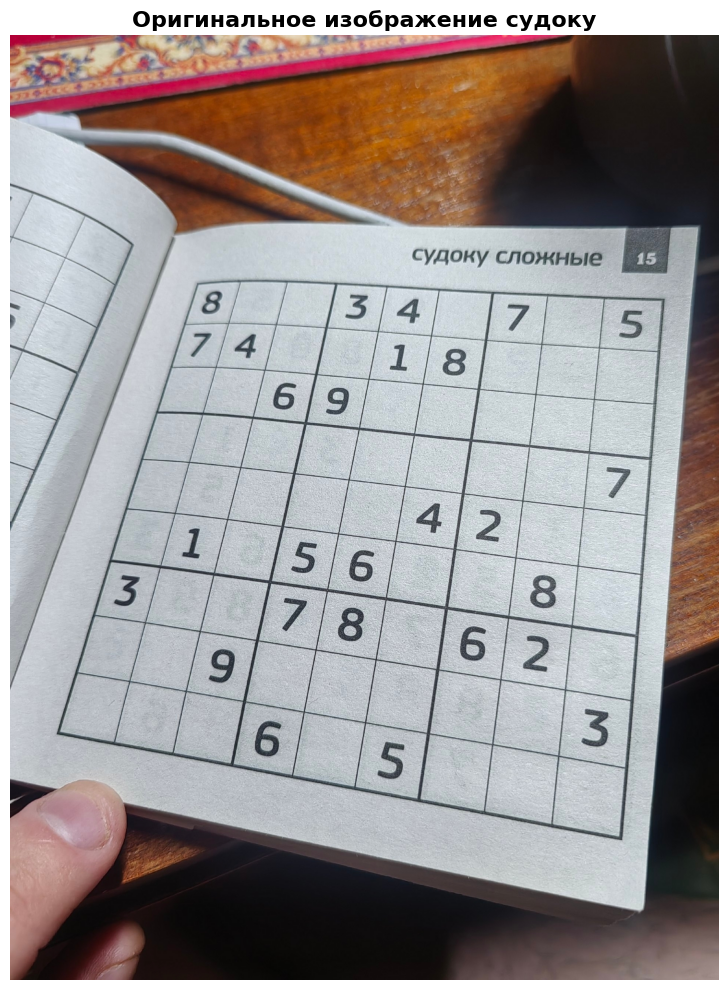

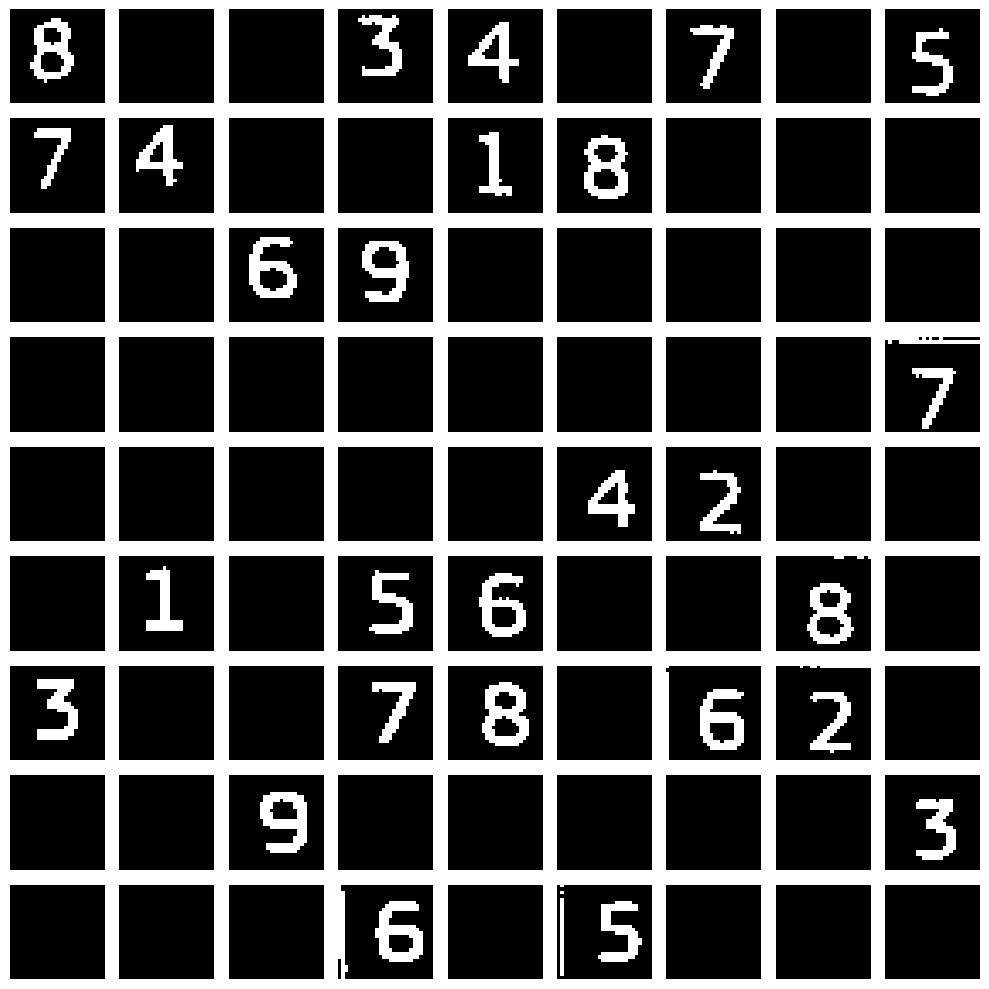

In [ ]:
path = '/content/drive/My Drive/Colab Notebooks/комп технологии/s.jpg'

img = cv2.imread(path)
if img is None:
    raise FileNotFoundError(f"Изображение не найдено по пути: {path}")

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Оригинальное изображение судоку", fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

# Извлечение клеток
cells_array, empty_grid = extract_sudoku_cells(path, visualize=True)

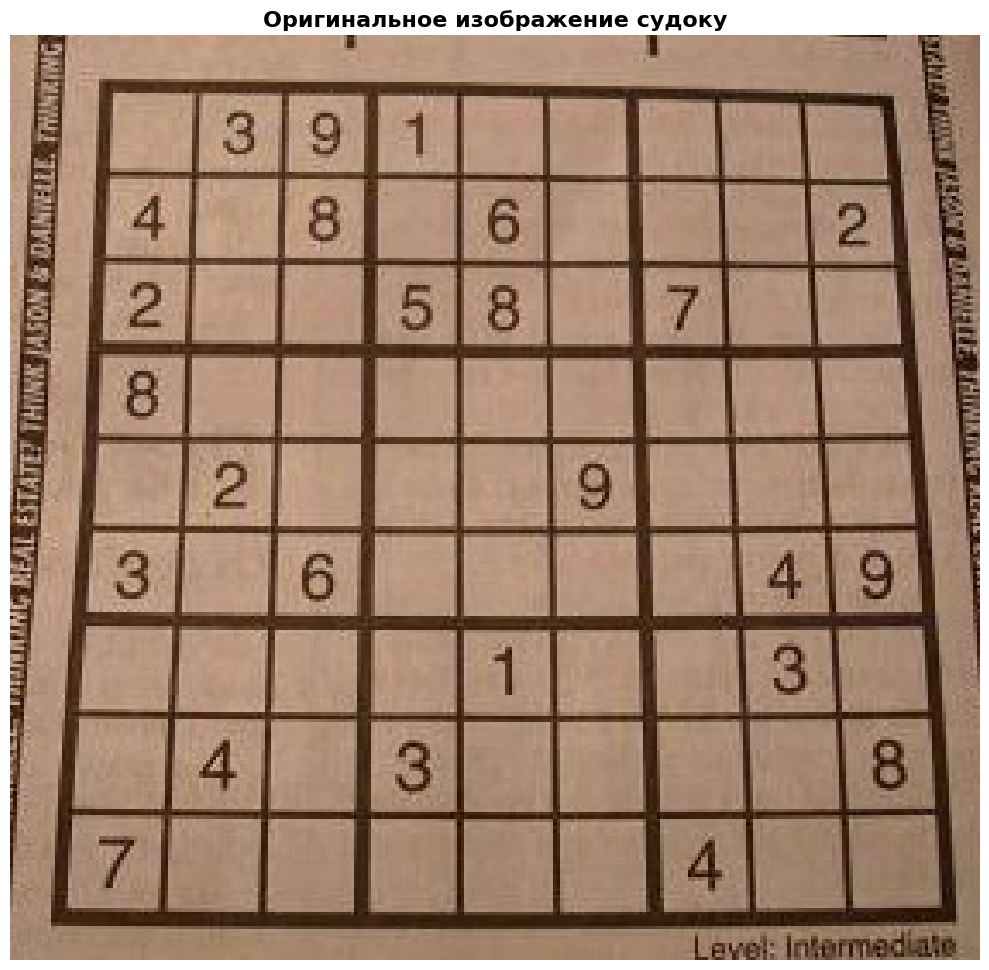

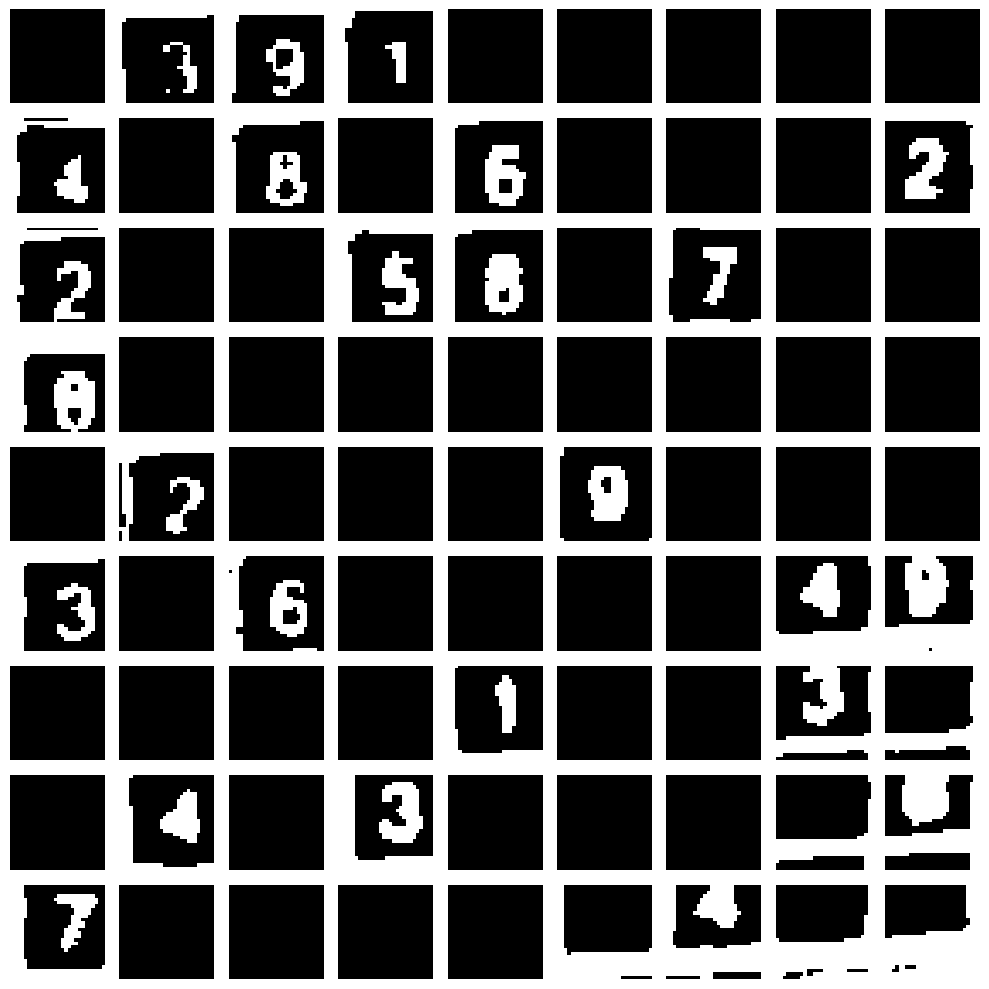

In [ ]:
path = '/content/drive/My Drive/Colab Notebooks/комп технологии/Sodoku.jpg'

img = cv2.imread(path)
if img is None:
    raise FileNotFoundError(f"Изображение не найдено по пути: {path}")

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Оригинальное изображение судоку", fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

# Извлечение клеток
cells_array, empty_grid = extract_sudoku_cells(path, visualize=True)

#нейронка


## обычная сверточная

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import numpy as np
import cv2

def create_model():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


# Инициализация и компиляция модели
model = create_model()
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Загрузка данных MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Нормализация и добавление канала глубины (28, 28) -> (28, 28, 1)
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# Обучение модели
print("Начало обучения модели...")
model.fit(
    x_train, y_train,
    epochs=100,
    batch_size=64,
    validation_data=(x_test, y_test),
    verbose=1
)

# Сохранение модели для последующего использования
model.save('sudoku_model.keras')
print("Модель успешно сохранена в 'sudoku_model.keras'")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Начало обучения модели...
Epoch 1/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9498 - loss: 0.1700 - val_accuracy: 0.9808 - val_loss: 0.0551
Epoch 2/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9851 - loss: 0.0490 - val_accuracy: 0.9865 - val_loss: 0.0381
Epoch 3/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9892 - loss: 0.0352 - val_accuracy: 0.9890 - val_loss: 0.0334
Epoch 4/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9916 - loss: 0.0267 - val_accuracy: 0.9862 - val_loss: 0.0407
Epoch 5/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9930 - loss: 0.0209 - val_accuracy: 0.9891 - val_loss: 0.0331
Epoch 6/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9950 - loss: 0.0158 - val_accuracy: 0.9889 - val_loss: 0.0341
Epoch 7/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9955 - loss: 0.0130 - val_accuracy: 0.9912 - val_loss: 0.0357
Epoch 8/100
938/93

In [ ]:
from google.colab import drive
import tensorflow as tf

drive.mount('/content/drive')

model_path = '/content/drive/My Drive/Colab Notebooks/комп технологии/sudoku_model.keras'
loaded_model = tf.keras.models.load_model(model_path)

loaded_model.summary()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 365,792 (1.40 MB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 243,862 (952.59 KB)

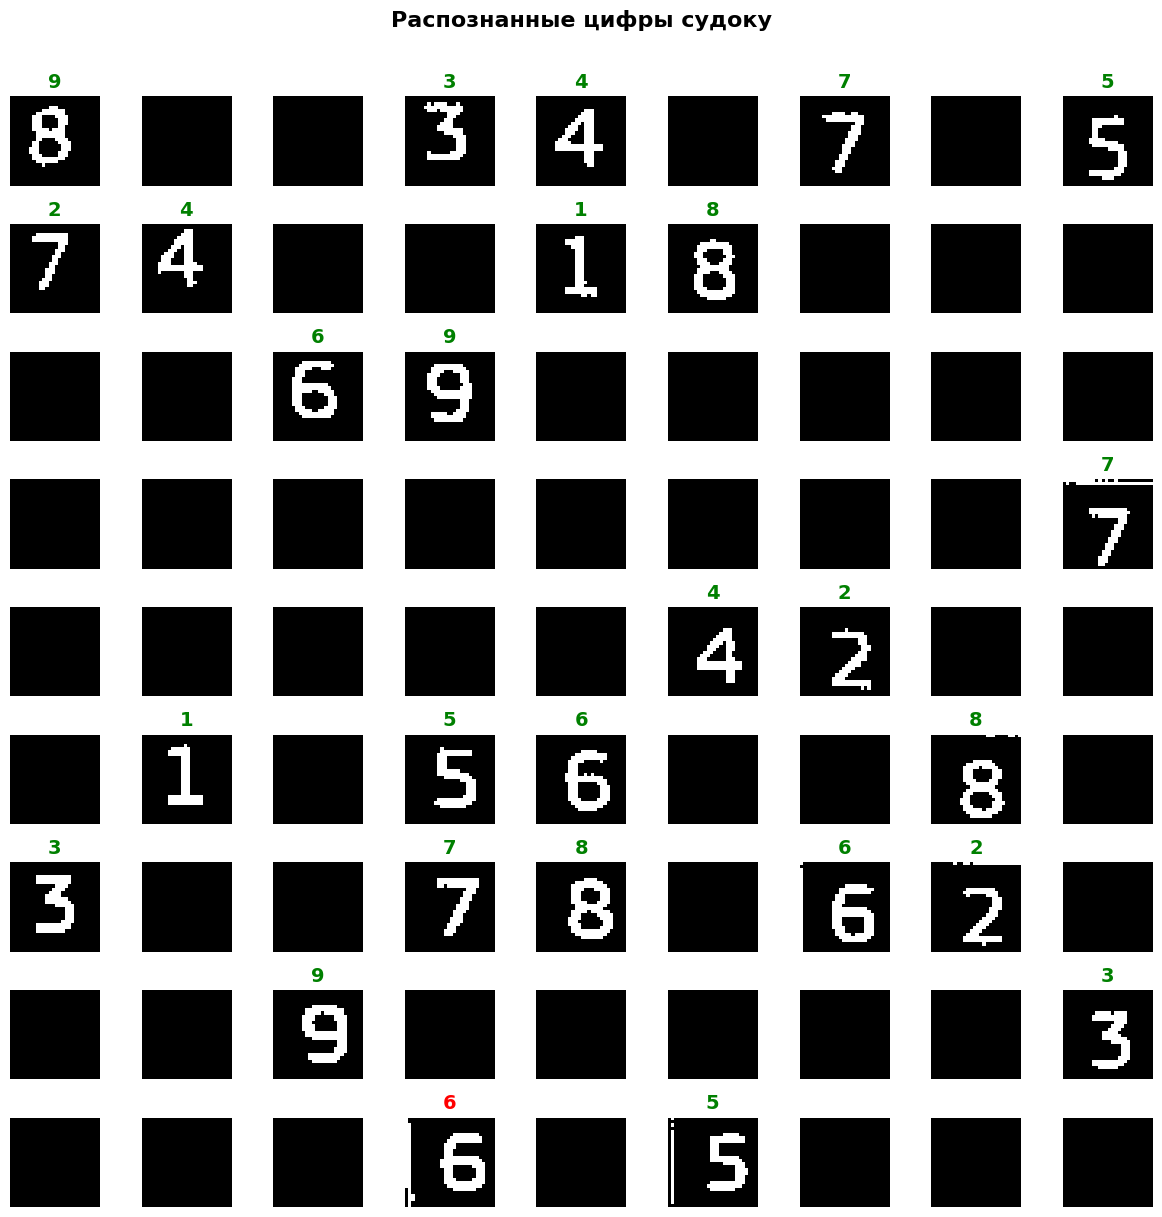


РАСПОЗНАННАЯ СЕТКА СУДОКУ:
9 . . | 3 4 . | 7 . 5 
2 4 . | . 1 8 | . . . 
. . 6 | 9 . . | . . . 
-------------------------
. . . | . . . | . . 7 
. . . | . . 4 | 2 . . 
. 1 . | 5 6 . | . 8 . 
-------------------------
3 . . | 7 8 . | 6 2 . 
. . 9 | . . . | . . 3 
. . . | 6 . 5 | . . . 


In [ ]:
def visualize_recognized_digits(cells, empty_mask, predictions, confidence, threshold=0.5):
    """
    Отображает распознанные цифры в виде сетки 9x9.

    Args:
        cells: массив изображений клеток (81, 28, 28)
        empty_mask: маска пустых клеток (9, 9)
        predictions: предсказанные цифры (81,)
        confidence: уверенность модели (81,)
        threshold: порог уверенности для отображения
    """
    fig, axes = plt.subplots(9, 9, figsize=(12, 12))
    axes = axes.ravel()
    null_img = np.zeros((28, 28), dtype=np.uint8)

    for i in range(81):
        row = i // 9
        col = i % 9
        is_empty = empty_mask[row, col]
        conf = confidence[i]

        if is_empty or conf < threshold:
            # Пустая клетка - черный квадрат без заголовка
            axes[i].imshow(null_img, cmap="gray", vmin=0, vmax=255)
            axes[i].set_title("", fontsize=10)
        else:
            # Клетка с цифрой
            axes[i].imshow(cells[i], cmap="gray", vmin=0, vmax=255)
            digit = predictions[i]

            # Цвет зависит от уверенности
            if conf >= 0.9:
                color = 'green'      # Высокая уверенность
            elif conf >= 0.7:
                color = 'orange'     # Средняя уверенность
            else:
                color = 'red'        # Низкая уверенность

            axes[i].set_title(f"{digit}", color=color, fontsize=14, fontweight='bold')

        axes[i].axis('off')

    plt.suptitle("Распознанные цифры судоку", fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


def print_sudoku_grid(empty_mask, predictions, confidence, threshold=0.5):
    """
    Выводит распознанную сетку судоку в текстовом виде.
    Пустые клетки отображаются как точка (.).
    """
    print("\nРАСПОЗНАННАЯ СЕТКА СУДОКУ:")
    print("=" * 25)

    grid = np.zeros((9, 9), dtype=int)

    for i in range(81):
        row = i // 9
        col = i % 9

        if not empty_mask[row, col] and confidence[i] >= threshold:
            grid[row, col] = predictions[i]

    # Красивый вывод с разделителями
    for i in range(9):
        if i % 3 == 0 and i != 0:
            print("-" * 25)

        row_str = ""
        for j in range(9):
            if j % 3 == 0 and j != 0:
                row_str += "| "

            cell_value = grid[i, j]

            # ИЗМЕНЕНИЕ: Если 0, выводим точку, иначе саму цифру
            display_char = "." if cell_value == 0 else str(cell_value)
            row_str += f"{display_char} "

        print(row_str)


model_path = '/content/drive/My Drive/Colab Notebooks/комп технологии/sudoku_model.keras'
loaded_model = tf.keras.models.load_model(model_path)

# Получаем предсказания
cells_normalized = cells_array.reshape(-1, 28, 28, 1).astype('float32') / 255.0
predictions = loaded_model.predict(cells_normalized, verbose=0)
predicted_digits = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1)

# Визуализация
visualize_recognized_digits(cells_array, empty_grid, predicted_digits, confidence_scores, threshold=0.5)

# Текстовый вывод
print_sudoku_grid(empty_grid, predicted_digits, confidence_scores, threshold=0.5)

## улучшенная

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import cv2
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def create_improved_model():
    """Улучшенная архитектура CNN с Dropout для лучшей генерализации."""
    model = models.Sequential([
        # Блок 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(28, 28, 1)),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Блок 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Блок 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Полносвязные слои
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


def generate_synthetic_digits(num_samples=50000):
    """
    Генерирует синтетические печатные цифры для дообучения.
    Использует разные шрифты и искажения.
    """
    from PIL import Image, ImageDraw, ImageFont
    import random

    X = []
    y = []

    # Создаем пустое изображение для шрифтов
    fonts = []
    for size in [20, 24, 28, 32]:
        try:
            # Попробуем разные шрифты
            fonts.append(ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", size))
        except:
            try:
                fonts.append(ImageFont.truetype("/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf", size))
            except:
                fonts.append(ImageFont.load_default())

    print("Генерация синтетических печатных цифр...")

    for i in range(num_samples):
        # Создаем черное изображение 28x28
        img = Image.new('L', (28, 28), color=0)
        draw = ImageDraw.Draw(img)

        # Выбираем случайную цифру и шрифт
        digit = i % 10
        font = random.choice(fonts)

        # Небольшое случайное смещение
        offset_x = random.randint(-2, 2)
        offset_y = random.randint(-2, 2)

        # Рисуем белую цифру
        draw.text((offset_x + 6, offset_y + 6), str(digit), font=font, fill=255)

        # Конвертируем в numpy array
        img_array = np.array(img).astype('float32') / 255.0

        X.append(img_array)
        y.append(digit)

        if (i + 1) % 10000 == 0:
            print(f"Сгенерировано {i + 1}/{num_samples} примеров")

    return np.array(X).reshape(-1, 28, 28, 1), np.array(y)


# ==========================================
# ОБУЧЕНИЕ УЛУЧШЕННОЙ МОДЕЛИ
# ==========================================

print("Создание улучшенной модели...")
model = create_improved_model()
model.summary()

# Загружаем MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# Генерируем синтетические печатные цифры
x_synthetic, y_synthetic = generate_synthetic_digits(50000)

# Объединяем данные
x_combined = np.vstack([x_train, x_synthetic])
y_combined = np.hstack([y_train, y_synthetic])

print(f"\nОбщий размер обучающей выборки: {len(x_combined)}")

# Аугментация данных
datagen = ImageDataGenerator(
    rotation_range=10,        # Поворот до 10 градусов
    width_shift_range=0.1,    # Сдвиг по ширине
    height_shift_range=0.1,   # Сдвиг по высоте
    zoom_range=0.1,           # Zoom
    shear_range=0.1,          # Shear
    fill_mode='nearest'
)

# Callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7
)

# Обучение
print("\nНачало обучения улучшенной модели...")
history = model.fit(
    datagen.flow(x_combined, y_combined, batch_size=128),
    epochs=50,
    validation_data=(x_test, y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

# Оценка
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nТочность на тестовой выборке: {test_acc*100:.2f}%")

# Сохранение
model.save('/content/drive/My Drive/Colab Notebooks/комп технологии/sudoku_model_improved.keras')
print("Улучшенная модель сохранена!")

Создание улучшенной модели...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           25

 Total params: 297,386 (1.13 MB)

 Trainable params: 296,362 (1.13 MB)

 Non-trainable params: 1,024 (4.00 KB)

Генерация синтетических печатных цифр...
Сгенерировано 10000/50000 примеров
Сгенерировано 20000/50000 примеров
Сгенерировано 30000/50000 примеров
Сгенерировано 40000/50000 примеров
Сгенерировано 50000/50000 примеров

Общий размер обучающей выборки: 110000

Начало обучения улучшенной модели...
Epoch 1/50
860/860 ━━━━━━━━━━━━━━━━━━━━ 76s 66ms/step - accuracy: 0.8470 - loss: 0.4885 - val_accuracy: 0.9851 - val_loss: 0.0464 - learning_rate: 0.0010
Epoch 2/50
860/860 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.9742 - loss: 0.0909 - val_accuracy: 0.9891 - val_loss: 0.0302 - learning_rate: 0.0010
Epoch 3/50
860/860 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.9819 - loss: 0.0637 - val_accuracy: 0.9920 - val_loss: 0.0238 - learning_rate: 0.0010
Epoch 4/50
860/860 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.9849 - loss: 0.0535 - val_accuracy: 0.9890 - val_loss: 0.0323 - learning_rate: 0.0010
Epoch 5/50
860/860 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.9870 - loss: 0.0478 - 

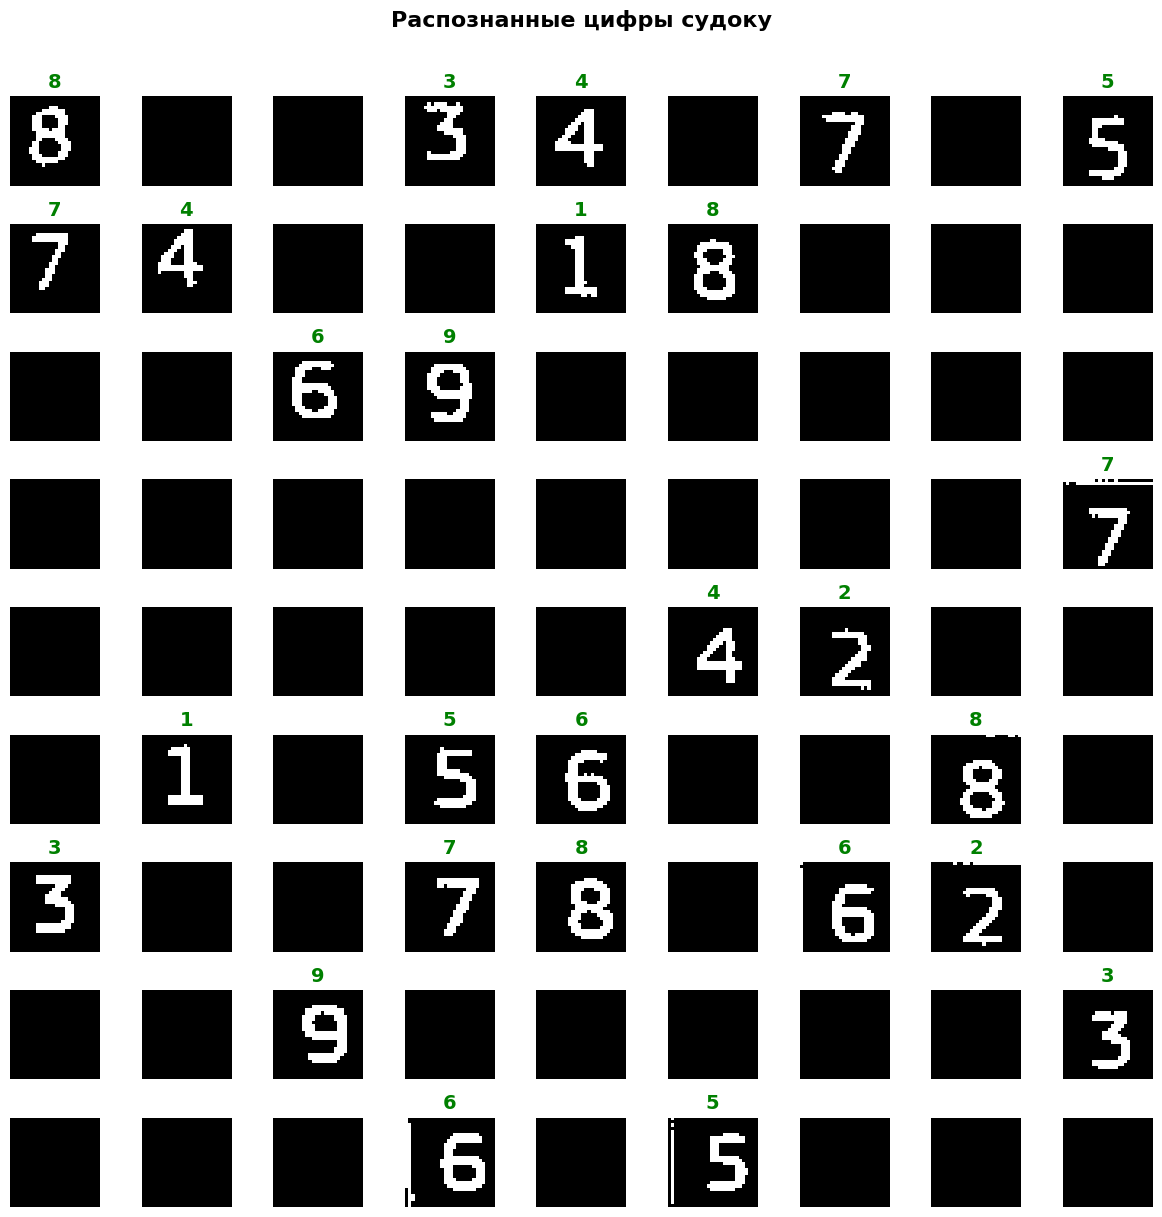


РАСПОЗНАННАЯ СЕТКА СУДОКУ:
8 . . | 3 4 . | 7 . 5 
7 4 . | . 1 8 | . . . 
. . 6 | 9 . . | . . . 
-------------------------
. . . | . . . | . . 7 
. . . | . . 4 | 2 . . 
. 1 . | 5 6 . | . 8 . 
-------------------------
3 . . | 7 8 . | 6 2 . 
. . 9 | . . . | . . 3 
. . . | 6 . 5 | . . . 


In [ ]:
def visualize_recognized_digits(cells, empty_mask, predictions, confidence, threshold=0.5):
    """
    Отображает распознанные цифры в виде сетки 9x9.

    Args:
        cells: массив изображений клеток (81, 28, 28)
        empty_mask: маска пустых клеток (9, 9)
        predictions: предсказанные цифры (81,)
        confidence: уверенность модели (81,)
        threshold: порог уверенности для отображения
    """
    fig, axes = plt.subplots(9, 9, figsize=(12, 12))
    axes = axes.ravel()
    null_img = np.zeros((28, 28), dtype=np.uint8)

    for i in range(81):
        row = i // 9
        col = i % 9
        is_empty = empty_mask[row, col]
        conf = confidence[i]

        if is_empty or conf < threshold:
            # Пустая клетка - черный квадрат без заголовка
            axes[i].imshow(null_img, cmap="gray", vmin=0, vmax=255)
            axes[i].set_title("", fontsize=10)
        else:
            # Клетка с цифрой
            axes[i].imshow(cells[i], cmap="gray", vmin=0, vmax=255)
            digit = predictions[i]

            # Цвет зависит от уверенности
            if conf >= 0.9:
                color = 'green'      # Высокая уверенность
            elif conf >= 0.7:
                color = 'orange'     # Средняя уверенность
            else:
                color = 'red'        # Низкая уверенность

            axes[i].set_title(f"{digit}", color=color, fontsize=14, fontweight='bold')

        axes[i].axis('off')

    plt.suptitle("Распознанные цифры судоку", fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


def print_sudoku_grid(empty_mask, predictions, confidence, threshold=0.5):
    """
    Выводит распознанную сетку судоку в текстовом виде.
    Пустые клетки отображаются как точка (.).
    """
    print("\nРАСПОЗНАННАЯ СЕТКА СУДОКУ:")
    print("=" * 25)

    grid = np.zeros((9, 9), dtype=int)

    for i in range(81):
        row = i // 9
        col = i % 9

        if not empty_mask[row, col] and confidence[i] >= threshold:
            grid[row, col] = predictions[i]

    # Красивый вывод с разделителями
    for i in range(9):
        if i % 3 == 0 and i != 0:
            print("-" * 25)

        row_str = ""
        for j in range(9):
            if j % 3 == 0 and j != 0:
                row_str += "| "

            cell_value = grid[i, j]

            # ИЗМЕНЕНИЕ: Если 0, выводим точку, иначе саму цифру
            display_char = "." if cell_value == 0 else str(cell_value)
            row_str += f"{display_char} "

        print(row_str)


model_path = '/content/drive/My Drive/Colab Notebooks/комп технологии/sudoku_model_improved.keras'
loaded_model = tf.keras.models.load_model(model_path)

# Получаем предсказания
cells_normalized = cells_array.reshape(-1, 28, 28, 1).astype('float32') / 255.0
predictions = loaded_model.predict(cells_normalized, verbose=0)
predicted_digits = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1)

# Визуализация
visualize_recognized_digits(cells_array, empty_grid, predicted_digits, confidence_scores, threshold=0.5)

# Текстовый вывод
print_sudoku_grid(empty_grid, predicted_digits, confidence_scores, threshold=0.5)

# прмер


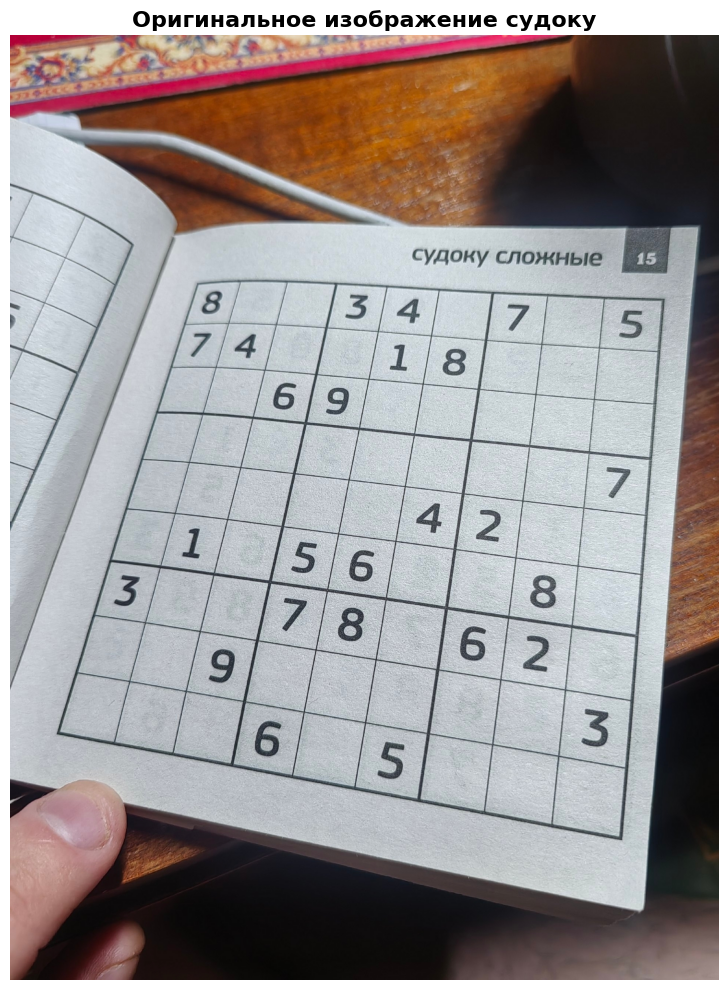

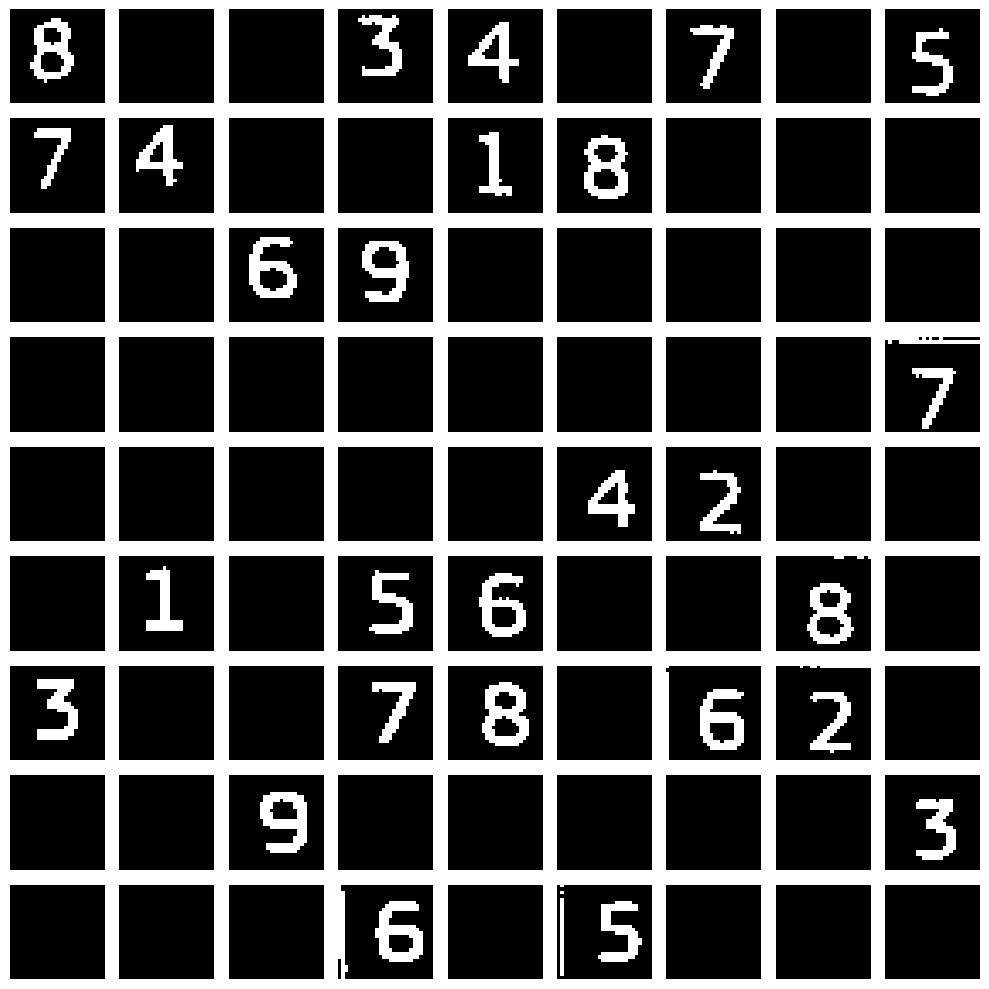

In [ ]:
path = '/content/drive/My Drive/Colab Notebooks/комп технологии/s.jpg'

img = cv2.imread(path)
if img is None:
    raise FileNotFoundError(f"Изображение не найдено по пути: {path}")

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Оригинальное изображение судоку", fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

# Извлечение клеток
cells_array, empty_grid = extract_sudoku_cells(path, visualize=True)

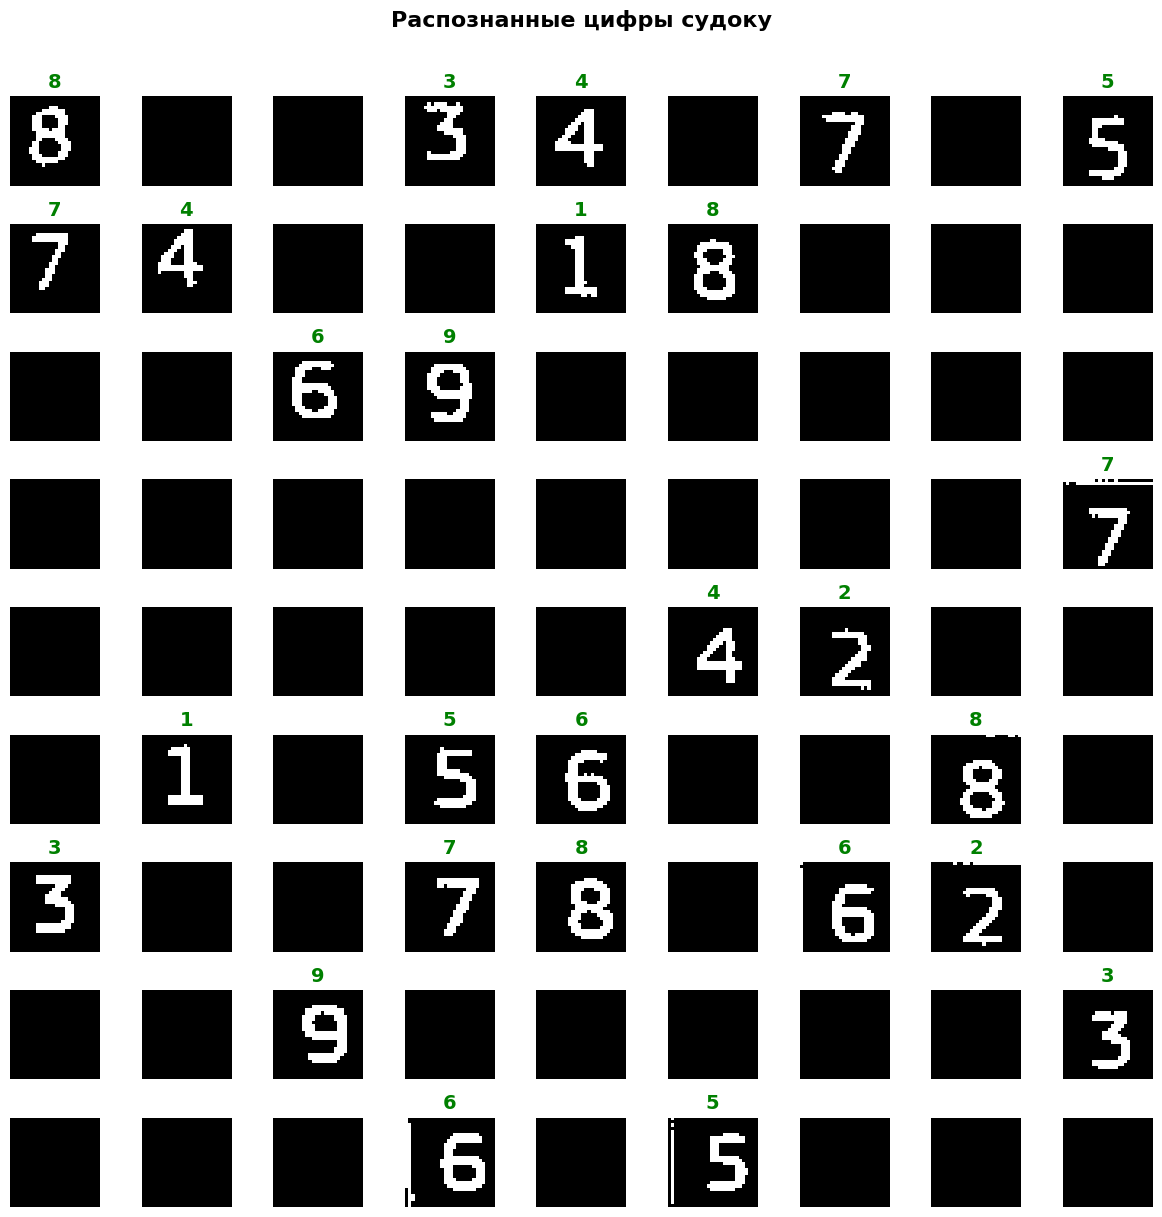


РАСПОЗНАННАЯ СЕТКА СУДОКУ:
8 . . | 3 4 . | 7 . 5 
7 4 . | . 1 8 | . . . 
. . 6 | 9 . . | . . . 
-------------------------
. . . | . . . | . . 7 
. . . | . . 4 | 2 . . 
. 1 . | 5 6 . | . 8 . 
-------------------------
3 . . | 7 8 . | 6 2 . 
. . 9 | . . . | . . 3 
. . . | 6 . 5 | . . . 


In [ ]:
model_path = '/content/drive/My Drive/Colab Notebooks/комп технологии/sudoku_model_improved.keras'
loaded_model = tf.keras.models.load_model(model_path)

# Получаем предсказания
cells_normalized = cells_array.reshape(-1, 28, 28, 1).astype('float32') / 255.0
predictions = loaded_model.predict(cells_normalized, verbose=0)
predicted_digits = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1)

# Визуализация
visualize_recognized_digits(cells_array, empty_grid, predicted_digits, confidence_scores, threshold=0.5)

# Текстовый вывод
print_sudoku_grid(empty_grid, predicted_digits, confidence_scores, threshold=0.5)

In [ ]:
def convert_to_solver_format(empty_mask, predictions, confidence, threshold=0.5):
    """
    Преобразует распознанное судоку в формат для решателя.
    Пустые клетки -> '.', заполненные -> строка с цифрой.
    """
    grid = [['.' for _ in range(9)] for _ in range(9)]

    for i in range(81):
        row = i // 9
        col = i % 9

        if not empty_mask[row, col] and confidence[i] >= threshold:
            grid[row][col] = str(predictions[i])

    return grid

sudoku_grid = convert_to_solver_format(
    empty_grid,
    predicted_digits,
    confidence_scores,
    threshold=0.5
)

print("\nРаспознанное судоку (перед решением):")
print_grid(sudoku_grid)

# Решаем
solve(sudoku_grid)
print_grid(sudoku_grid)




Распознанное судоку (перед решением):
8 . . | 3 4 . | 7 . 5
7 4 . | . 1 8 | . . .
. . 6 | 9 . . | . . .
---------------------
. . . | . . . | . . 7
. . . | . . 4 | 2 . .
. 1 . | 5 6 . | . 8 .
---------------------
3 . . | 7 8 . | 6 2 .
. . 9 | . . . | . . 3
. . . | 6 . 5 | . . .

8 9 2 | 3 4 6 | 7 1 5
7 4 5 | 2 1 8 | 9 3 6
1 3 6 | 9 5 7 | 8 4 2
---------------------
5 2 8 | 1 9 3 | 4 6 7
9 6 3 | 8 7 4 | 2 5 1
4 1 7 | 5 6 2 | 3 8 9
---------------------
3 5 1 | 7 8 9 | 6 2 4
6 8 9 | 4 2 1 | 5 7 3
2 7 4 | 6 3 5 | 1 9 8



#1 (можно не смотреть)

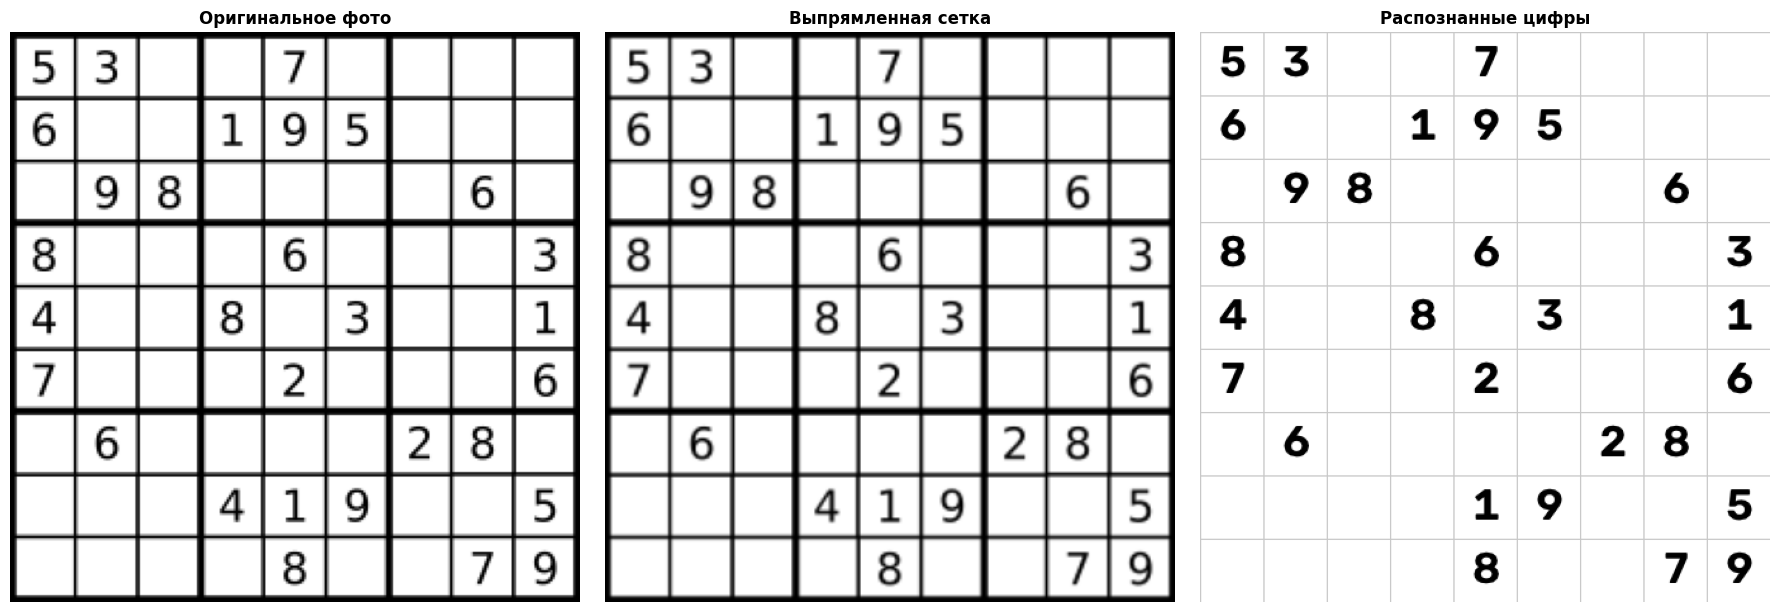


РАСПОЗНАННАЯ СЕТКА:
5 3 . . 7 . . . .
6 . . 1 9 5 . . .
. 9 8 . . . . 6 .
-----------------------
8 . . . 6 . . . 3
4 . . 8 . 3 . . 1
7 . . . 2 . . . 6
-----------------------
. 6 . . . . 2 8 .
. . . . 1 9 . . 5
. . . . 8 . . 7 9


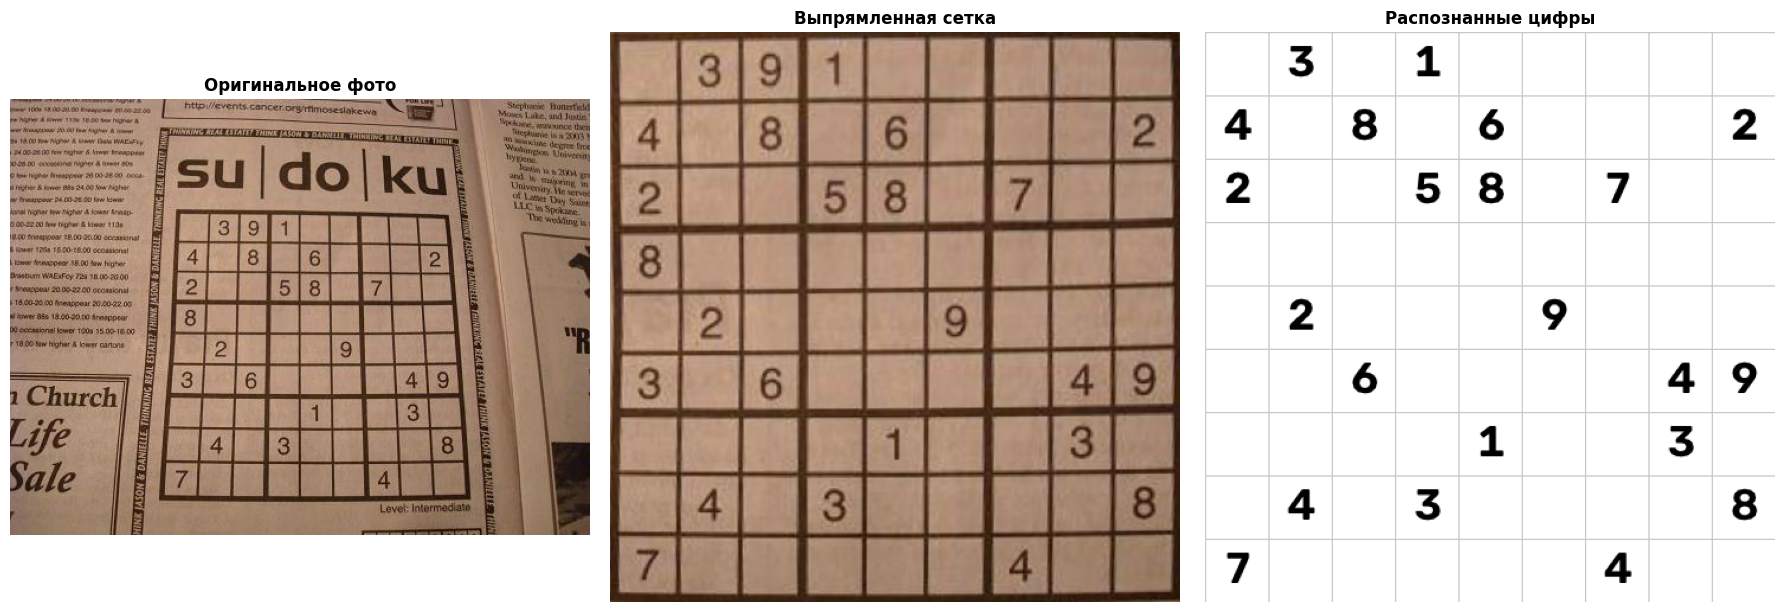


РАСПОЗНАННАЯ СЕТКА:
. 3 . 1 . . . . .
4 . 8 . 6 . . . 2
2 . . 5 8 . 7 . .
-----------------------
. . . . . . . . .
. 2 . . . 9 . . .
. . 6 . . . . 4 9
-----------------------
. . . . 1 . . 3 .
. 4 . 3 . . . . 8
7 . . . . . 4 . .


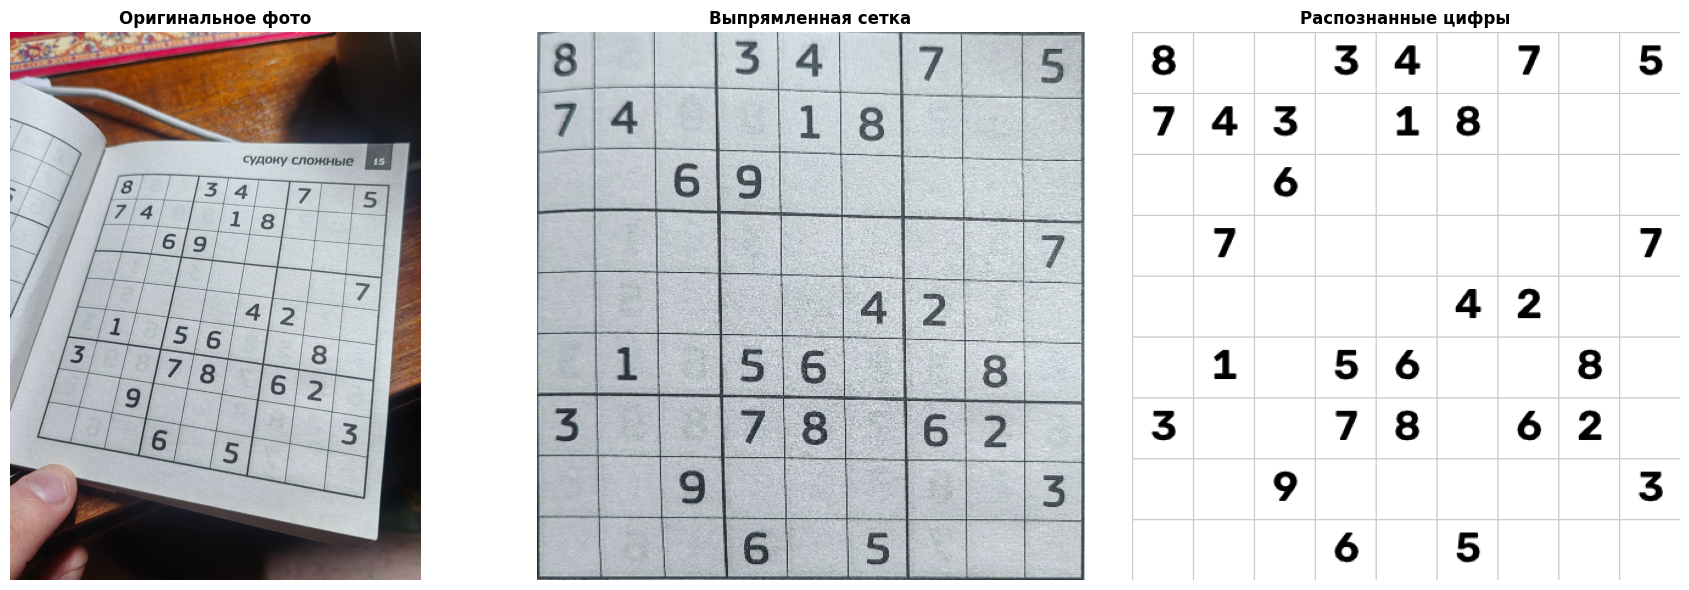


РАСПОЗНАННАЯ СЕТКА:
8 . . 3 4 . 7 . 5
7 4 3 . 1 8 . . .
. . 6 . . . . . .
-----------------------
. 7 . . . . . . 7
. . . . . 4 2 . .
. 1 . 5 6 . . 8 .
-----------------------
3 . . 7 8 . 6 2 .
. . 9 . . . . . 3
. . . 6 . 5 . . .


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract

# ============================================================
# 1. НАСТРОЙКА TESSERACT
# ============================================================
# Установите tesseract если не установлен:
# !apt-get install tesseract-ocr
# !pip install pytesseract

pytesseract.pytesseract.tesseract_cmd = '/usr/bin/tesseract'

# ============================================================
# 2. ПОИСК И ВЫПРЯМЛЕНИЕ СЕТКИ
# ============================================================
def find_and_warp_sudoku(img):
    """Находит сетку судоку и выпрямляет её"""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Адаптивная бинаризация
    binary = cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, 11, 2
    )

    # Поиск контуров
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    max_area = 0
    best_cnt = None

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < 5000:
            continue

        peri = cv2.arcLength(cnt, True)
        approx = cv2.approxPolyDP(cnt, 0.04 * peri, True)

        if len(approx) == 4 and area > max_area:
            max_area = area
            best_cnt = approx

    if best_cnt is None:
        return None

    # Выпрямление
    pts = best_cnt.reshape(4, 2).astype("float32")
    s = pts.sum(axis=1)
    diff = np.diff(pts, axis=1)

    rect = np.zeros((4, 2), dtype="float32")
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]

    size = 450
    dst = np.array([[0,0], [size-1,0], [size-1,size-1], [0,size-1]], dtype="float32")
    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(img, M, (size, size))

    return warped

# ============================================================
# 3. РАСПОЗНАВАНИЕ ЦИФР ЧЕРЕЗ TESSERACT
# ============================================================
def recognize_digits_tesseract(warped_img):
    """Распознаёт цифры используя Tesseract OCR"""
    h, w = warped_img.shape[:2]
    cell_h = h // 9
    cell_w = w // 9

    digits = np.zeros((9, 9), dtype=int)

    for row in range(9):
        for col in range(9):
            y1 = row * cell_h
            y2 = (row + 1) * cell_h
            x1 = col * cell_w
            x2 = (col + 1) * cell_w

            cell = warped_img[y1:y2, x1:x2]

            # Предобработка ячейки
            digit = extract_digit_from_cell(cell)

            if digit is not None:
                digits[row, col] = digit
            else:
                digits[row, col] = 0

    return digits

def extract_digit_from_cell(cell):
    """Извлекает цифру из ячейки используя Tesseract"""
    if len(cell.shape) == 3:
        gray = cv2.cvtColor(cell, cv2.COLOR_BGR2GRAY)
    else:
        gray = cell.copy()

    # Убираем границы (где линии сетки)
    margin = max(3, gray.shape[0] // 10)
    roi = gray[margin:-margin, margin:-margin]

    # Бинаризация
    _, binary = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Проверяем, есть ли что-то в ячейке
    if np.sum(binary > 0) < binary.size * 0.05:
        return None

    # Морфологическая очистка
    kernel = np.ones((2, 2), np.uint8)
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

    # Находим контур цифры
    contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        return None

    largest = max(contours, key=cv2.contourArea)

    if cv2.contourArea(largest) < 50:
        return None

    # Вырезаем цифру
    x, y, w, h = cv2.boundingRect(largest)
    padding = 5
    digit_roi = cleaned[max(0,y-padding):min(cleaned.shape[0],y+h+padding),
                        max(0,x-padding):min(cleaned.shape[1],x+w+padding)]

    # Добавляем белые поля вокруг (Tesseract любит поля)
    padded = cv2.copyMakeBorder(digit_roi, 10, 10, 10, 10,
                                 cv2.BORDER_CONSTANT, value=0)

    # Инвертируем (Tesseract ожидает чёрный текст на белом фоне)
    digit_final = cv2.bitwise_not(padded)

    # Распознавание через Tesseract
    config = '--psm 10 -c tessedit_char_whitelist=0123456789'
    text = pytesseract.image_to_string(digit_final, config=config).strip()

    if text and text.isdigit():
        return int(text)

    return None

# ============================================================
# 4. ВИЗУАЛИЗАЦИЯ
# ============================================================
def visualize_results(original_img, warped, digits):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Оригинал
    axes[0].imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Оригинальное фото', fontsize=12, fontweight='bold')
    axes[0].axis('off')

    # Выпрямленная сетка
    axes[1].imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
    axes[1].set_title('Выпрямленная сетка', fontsize=12, fontweight='bold')
    axes[1].axis('off')

    # Распознанное
    cell_size = 50
    canvas = np.ones((450, 450, 3), dtype=np.uint8) * 255

    for row in range(9):
        for col in range(9):
            y1, y2 = row * cell_size, (row + 1) * cell_size
            x1, x2 = col * cell_size, (col + 1) * cell_size

            cv2.rectangle(canvas, (x1, y1), (x2, y2), (200, 200, 200), 1)

            digit = digits[row, col]
            if digit != 0:
                cv2.putText(canvas, str(digit), (x1+15, y1+35),
                           cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 2)

    axes[2].imshow(canvas)
    axes[2].set_title('Распознанные цифры', fontsize=12, fontweight='bold')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    # Вывод матрицы
    print("\n" + "="*40)
    print("РАСПОЗНАННАЯ СЕТКА:")
    print("="*40)
    for i, row in enumerate(digits):
        print(' '.join(str(x) if x != 0 else '.' for x in row))
        if (i + 1) % 3 == 0 and i < 8:
            print('-'*23)

# ============================================================
# 5. ЗАПУСК
# ============================================================

# Загрузка изображения
image_path = '/content/drive/My Drive/Colab Notebooks/комп технологии/Sudoku.png'
image_path1 = '/content/drive/My Drive/Colab Notebooks/комп технологии/Sodoku.jpg'
image_path2 = '/content/drive/My Drive/Colab Notebooks/комп технологии/s.jpg'

img = cv2.imread(image_path)
img1 = cv2.imread(image_path1)
img2 = cv2.imread(image_path2)

if img is None:
    raise FileNotFoundError("Изображение не найдено!")

# Предобработка
warped = find_and_warp_sudoku(img)
warped1 = find_and_warp_sudoku(img1)
warped2 = find_and_warp_sudoku(img2)

if warped is None:
    raise Exception("Не удалось найти сетку судоку!")

# Распознавание
digits = recognize_digits_tesseract(warped)
digits1 = recognize_digits_tesseract(warped1)
digits2 = recognize_digits_tesseract(warped2)

# Визуализация
visualize_results(img, warped, digits)
visualize_results(img1, warped1, digits1)
visualize_results(img2, warped2, digits2)